In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

import import_ipynb
import os

curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from BaseDataSet_Gen import NanoparticleDataFactory, AdvancedDataGenerator, get_preserved_mask, select_strict_basis_consistent
from BaseDataSet_Gen import plot_cn_distribution, plot_dataset_variability, plot_substructure_audit
from BaseDataSet_Gen import DummyFilter, MinMaxFilter, FCC_BulkCutFilter, CompositeFilter
os.chdir(curdir)

## Загрузим данные и определим необходимые переменные

In [2]:
SPECTRA_ROOT = Path('../processed_data/conv_dense_spectra/')

N_SAMPLES = 30000

UNIQUE_SUBSTRUCTURES = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')

SUB_SIZES = UNIQUE_SUBSTRUCTURES.Num_atoms.values

NP_BASIS_DF = pd.read_pickle('../source_data/NP_basis_representation_from_substructures.pkl')

WEIGHTS_MATRIX = np.stack(NP_BASIS_DF['Weighted_vector'].values)
NP_SIZES = WEIGHTS_MATRIX.sum(axis=1).astype(int)

NORMALISED_WEIGHTS = WEIGHTS_MATRIX / WEIGHTS_MATRIX.sum(axis=1, keepdims=True)

SAVE_DATA_PATH = Path('../processed_data/DataSets/')
FIG_SAVE_PATH = Path('../processed_data/DataSets/images/')

## Генерация данных

In [3]:
# Инициализация фабрики
e_grid = np.arange(-10, 60.1, 0.5) # Задаем сетку энергии для XANES спектров
factory = NanoparticleDataFactory(energy_grid=e_grid)

In [4]:
# Загрузка базиса
# Мы извлекаем CN для 7 сфер и интерполируем спектры
factory.load_basis(spectra_dir=SPECTRA_ROOT, 
                   substruct_df=UNIQUE_SUBSTRUCTURES, 
                   n_spheres=7 # Контроль кол-ва сфер.
                  )


Готово. В базисе 2151 подструктур.


### Scenario 1: Генерация наборов данных только из "синтетических" НЧ без аугментаций. 

In [5]:
gen = AdvancedDataGenerator(factory, sigma=0.08, n_delta=4, aug_params=None)

In [6]:
# 1. ПОДГОТОВКА БАЗИСА (220 элементов)
train_basis_idx, test_basis_idx = select_strict_basis_consistent(UNIQUE_SUBSTRUCTURES, n_target=220, train_ratio=0.5)
full_220_idx = np.concatenate([train_basis_idx, test_basis_idx])
print(f'{train_basis_idx.shape=}')
print(f'{test_basis_idx.shape=}')
print(f'{full_220_idx.shape=}')

train_basis_idx.shape=(110,)
test_basis_idx.shape=(110,)
full_220_idx.shape=(220,)


#### Scenario 1A - генерация как у Яниса, случайное замешивание по 3 подструктуры из всего набора, разбиение на уровне НЧ (возможна утечка);

In [7]:
%%time
X_1A_all, y_1A_all, w_1A_all = gen.generate_synthetic_set(full_220_idx, n_samples=N_SAMPLES, return_weights=True)
indecies = np.arange(X_1A_all.shape[0])
X_1A_train, X_1A_test, y_1A_train, y_1A_test, ind_tr, ind_te = train_test_split(X_1A_all, y_1A_all, indecies, test_size=0.2, random_state=42)

CPU times: total: 1min 12s
Wall time: 1min 12s


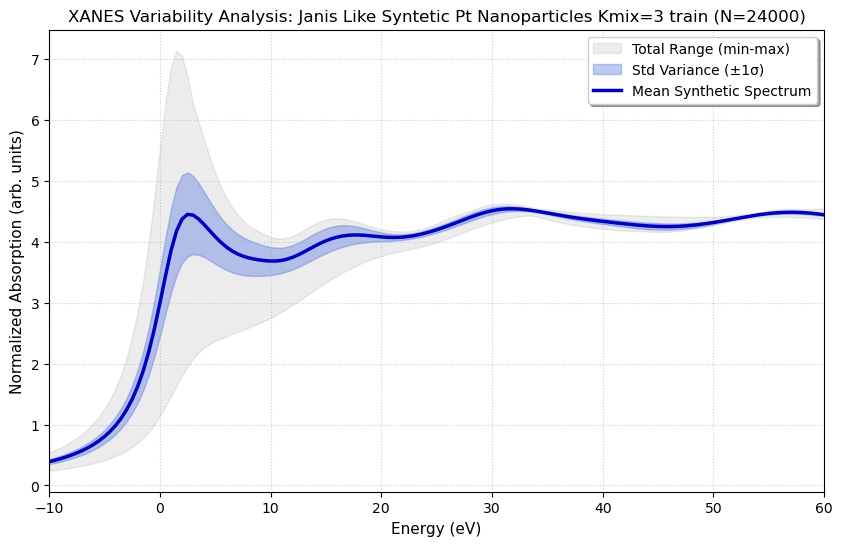

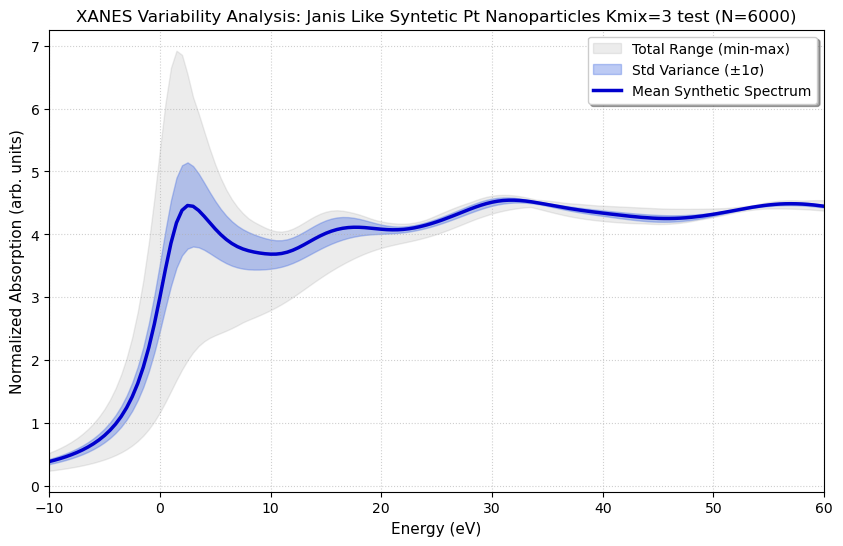

Y_train:


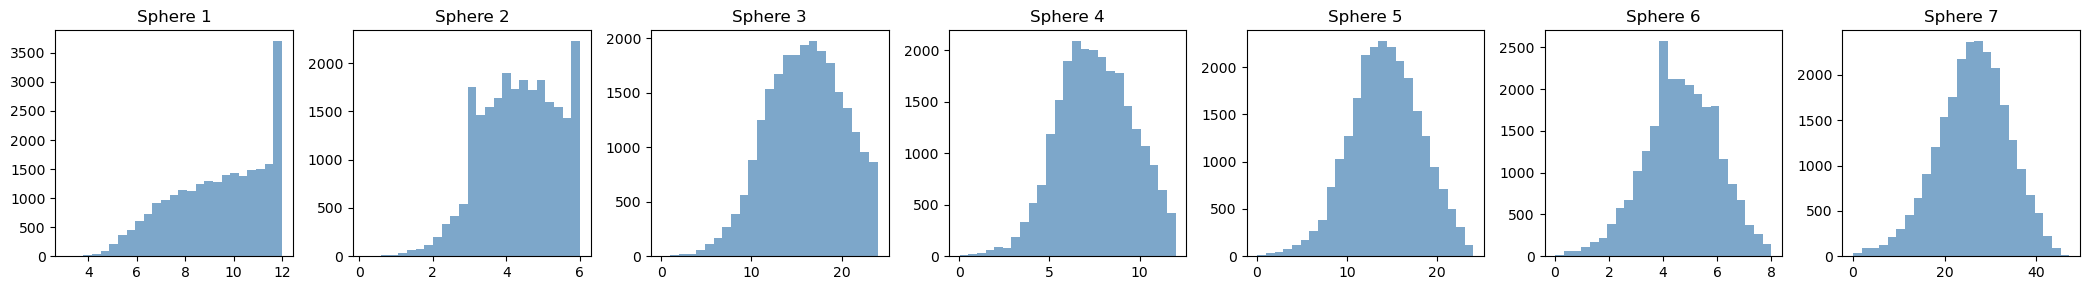

Y_test:


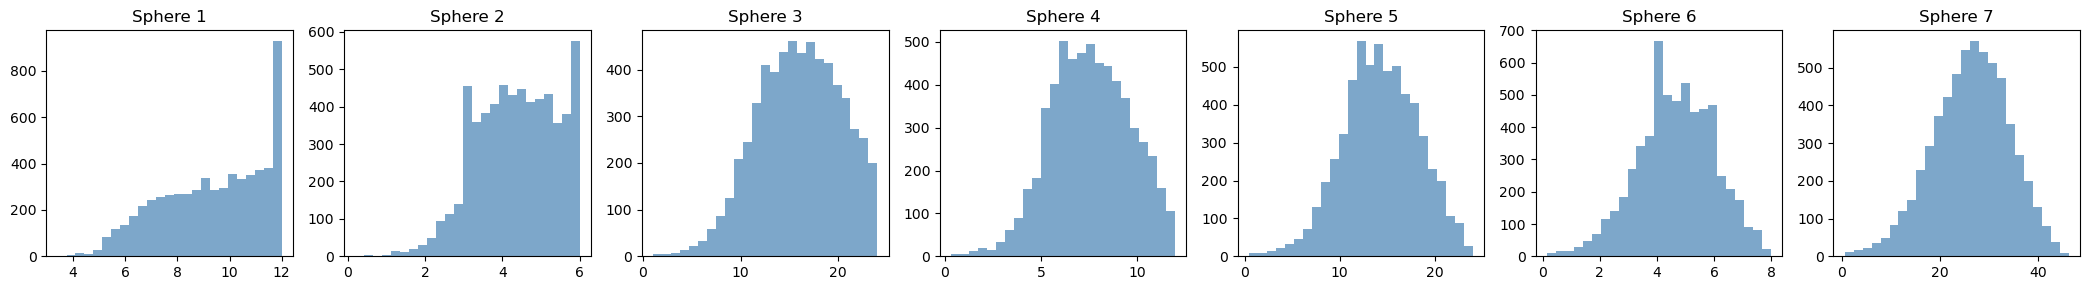

Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 220 (пустые 1931 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


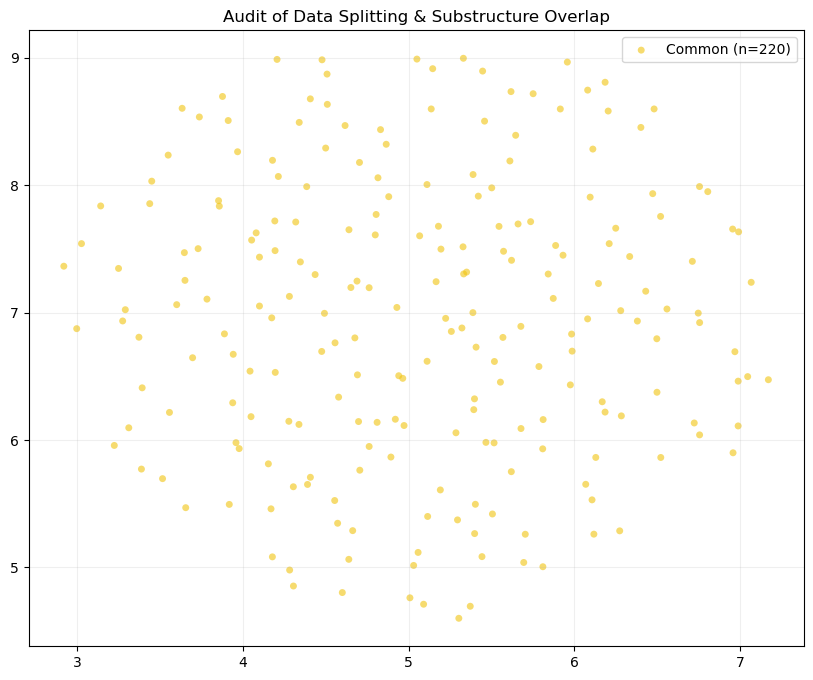

CPU times: total: 33.3 s
Wall time: 32.6 s


In [8]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Scenario_1A_Janis_like'))

plot_dataset_variability(X_data=X_1A_train, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Janis Like Syntetic Pt Nanoparticles Kmix=3 train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_1A_test, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Janis Like Syntetic Pt Nanoparticles Kmix=3 test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_1A_train,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_1A_test,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=w_1A_all, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')

In [9]:
np.savez(Path(SAVE_DATA_PATH, 'JanisLike_Train_X'), X_1A_train) 
np.savez(Path(SAVE_DATA_PATH, 'JanisLike_Test_X'), X_1A_test)
np.savez(Path(SAVE_DATA_PATH, 'JanisLike_Train_y'), y_1A_train)
np.savez(Path(SAVE_DATA_PATH, 'JanisLike_Test_y'), y_1A_test) 

#### Scenario 1B - случайное замешивание по 3 подструктуры, трейн из трейн набора, тест из тест набора.

In [10]:
%%time
X_1B_train, y_1B_train, w_1B_tr = gen.generate_synthetic_set(train_basis_idx, n_samples=int(N_SAMPLES*0.8), return_weights=True)
X_1B_test, y_1B_test, w_1B_te = gen.generate_synthetic_set(test_basis_idx, n_samples=int(N_SAMPLES*0.2), return_weights=True)

w_1B_all = np.concatenate((w_1B_tr,w_1B_te))
ind_tr = np.arange(w_1B_tr.shape[0])
ind_te = np.arange(w_1B_tr.shape[0],w_1B_all.shape[0],1)

CPU times: total: 1min 12s
Wall time: 1min 12s


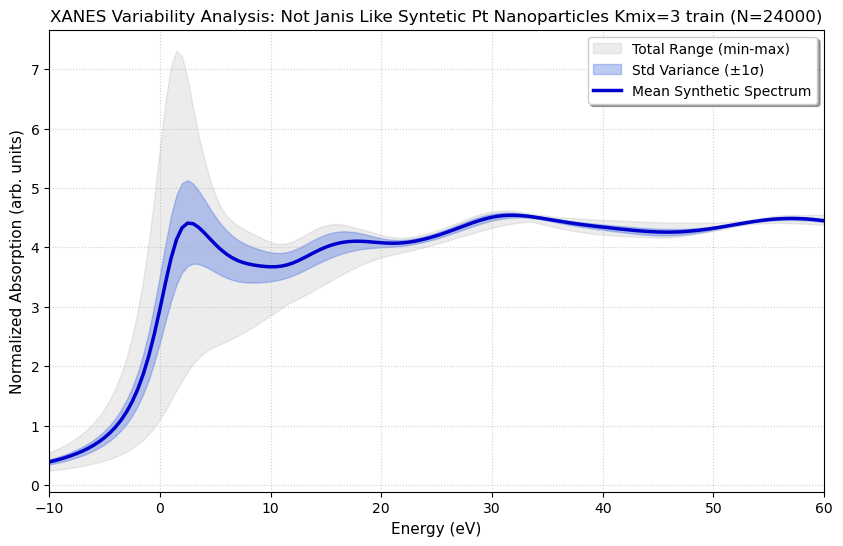

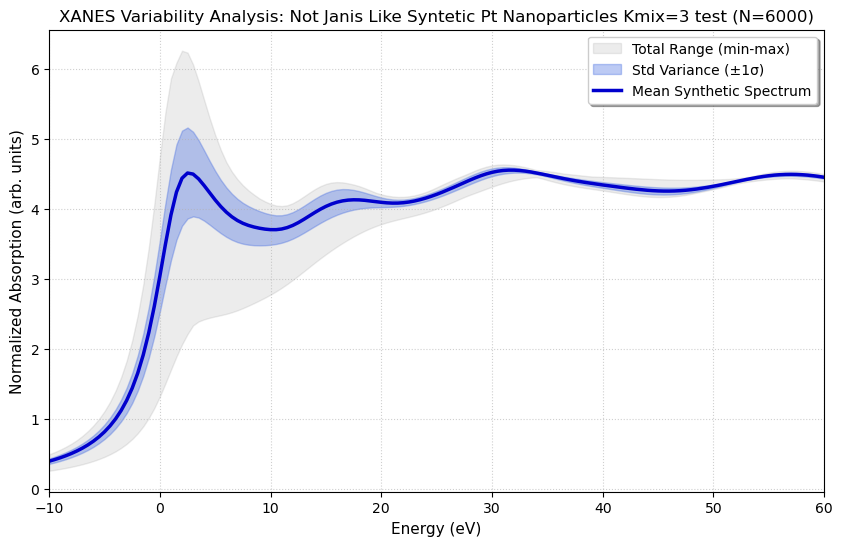

Y_train:


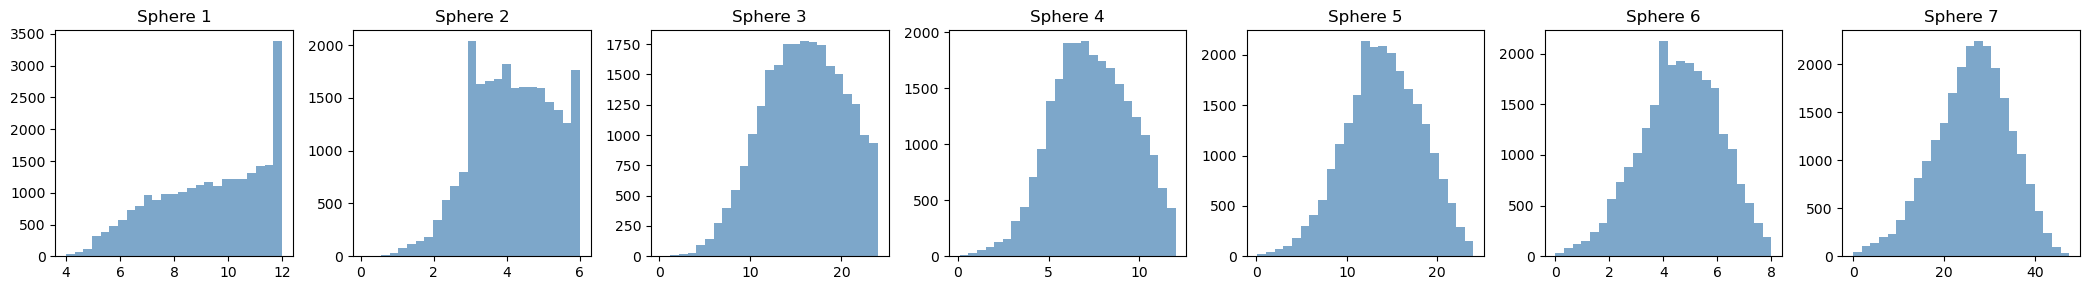

Y_test:


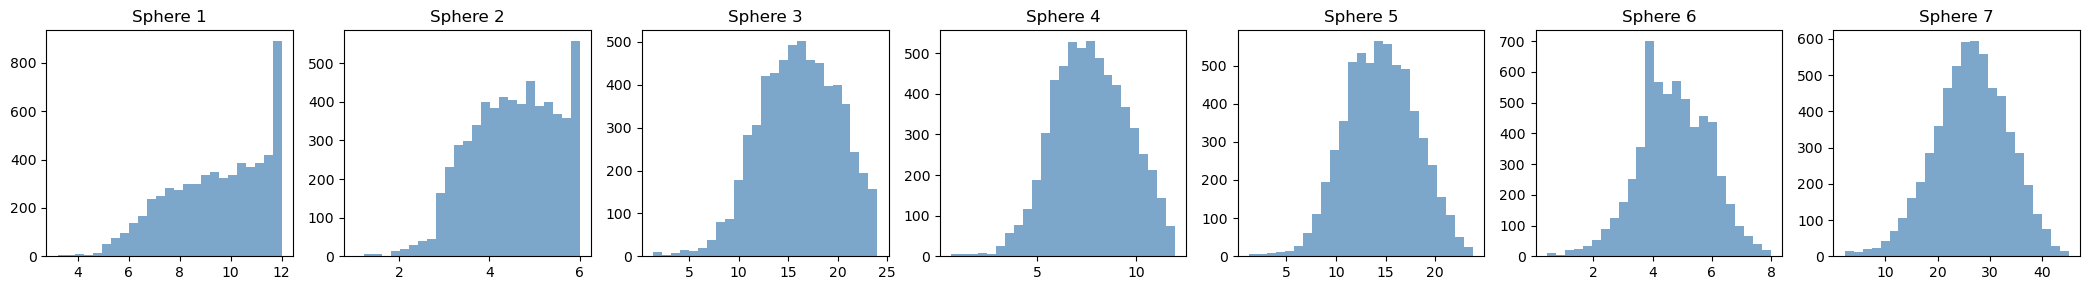

Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 220 (пустые 1931 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


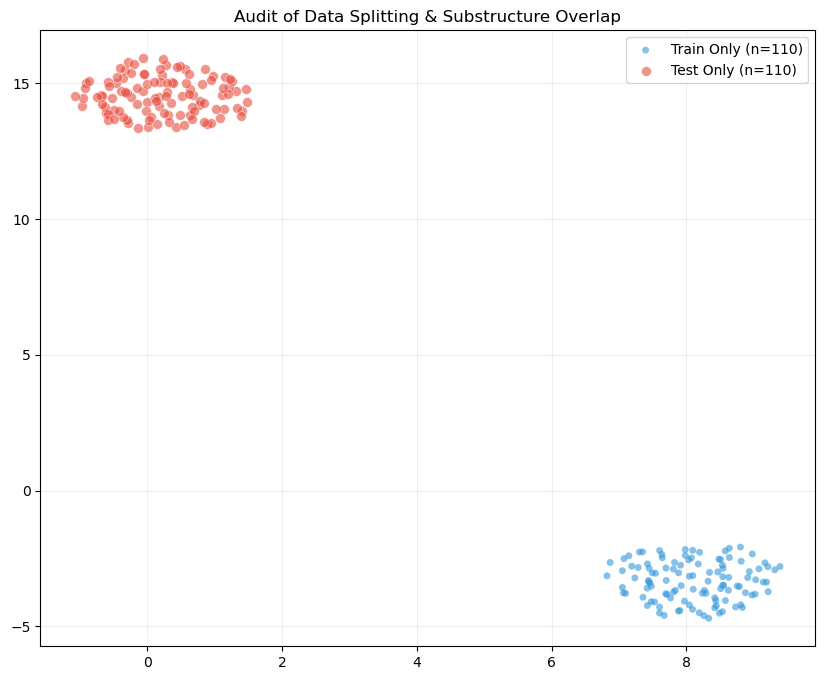

CPU times: total: 14.8 s
Wall time: 11.8 s


In [11]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Scenario_1B_NotJanis_like'))

plot_dataset_variability(X_data=X_1B_train, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Not Janis Like Syntetic Pt Nanoparticles Kmix=3 train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_1B_test, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Not Janis Like Syntetic Pt Nanoparticles Kmix=3 test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_1B_train,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_1B_test,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=w_1B_all, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')


In [12]:
np.savez(Path(SAVE_DATA_PATH, 'NotJanisLike_Train_X'), X_1B_train)
np.savez(Path(SAVE_DATA_PATH, 'NotJanisLike_Train_y'), y_1B_train)
np.savez(Path(SAVE_DATA_PATH, 'NotJanisLike_Test_X'), X_1B_test)
np.savez(Path(SAVE_DATA_PATH, 'NotJanisLike_Test_y'), y_1B_test)

### Scenario 2: Генерация наборов данных с реальными прообразами НЧ.

СТАТИСТИКА СООБЩЕСТВ И РАЗБИЕНИЯ ВЫБОРКИ:
Объектов в Train: 725 | Объектов в Test: 75
Размер базиса подструктур: 2151 | Пересекающиеся подструктуры: 452 (21.0%)
Уникально подструктур в Train: 1240 | Уникально в Test: 459
Доля Test выборки внутри интервала [0.03,0.97] Train данных: 0.947
Кол-во краевых малых НЧ в Test выборке (ниже 0.03 квантиля Train): 0
Кол-во краевых крупных НЧ в Test выборке (выше 0.97 квантиля Train): 4
Находятся ли краевые значения Test данных полностью внутри Train данных: True
Тест Колмогорова-Смирнова  для размеров НЧ (Train==Test): 0.28598 | P-value: 0.00002
Тест Колмогорова-Смирнова  для размеров НЧ (Train>=Test): 0.05563 | P-value: 0.63047
Тест Колмогорова-Смирнова  для размеров НК (Train==Test): 0.06271 | P-value: 0.11208
Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): 0.05292 | P-value: 0.12676
Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 2151 (пустые 0 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


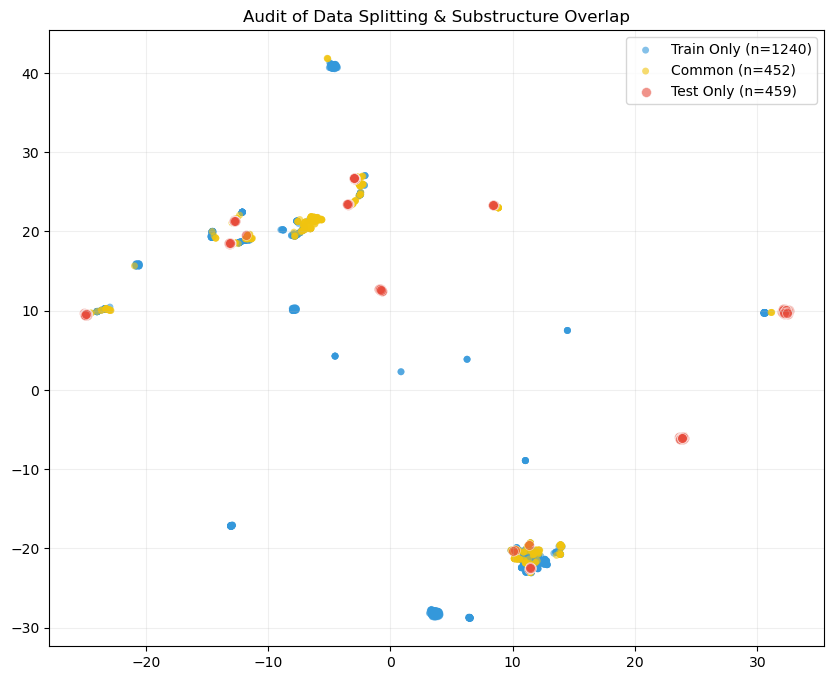

In [13]:
gen = AdvancedDataGenerator(factory, sigma=0.08, n_delta=4, aug_params=None)

guaranteed_train_samples_idx = get_preserved_mask(weights_matrix=WEIGHTS_MATRIX,
                                                  sub_sizes=SUB_SIZES,
                                                  reconstruction_n_comp=2,        # Число компонент для PCA оценки ошибки реконструкции
                                                  reconstruction_top_repcent=3.0, # сколько топ % брать 
                                                  low_size_percentile=3.0,        # сколько % самых малых НЧ брать
                                                  high_size_percentile=0.1,       # сколько % самых крупных НЧ брать
                                                  masks_priorities=[3,2,1,0],     # [con_comp, recon_err, low_prc, high_prc]
                                                  max_base_percentile=5.0,        # Допустимый % данных для отобранных НЧ
                                                  max_tail_percentile=3.0,        # Допустимый процент "хвоста" для отобранных данных
                                                  tail_threshold=0.65,            # Порог вовлеченности подструктур чтобы затянуть в трейн
                                                  verbose=0, 
                                                  seed=42)

tr_sample_idx, ts_sample_idx, tr_sub_idx, ts_sub_idx, shared_idx = factory.get_community_split(
                                                                           WEIGHTS_MATRIX,
                                                                           resolution=2.5,
                                                                           threshold=0.75, 
                                                                           guaranteed_train_samples_idx = guaranteed_train_samples_idx,
                                                                           sub_sizes = SUB_SIZES,
                                                                           seed=123,
                                                                           return_shared_idx=True)

plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=tr_sample_idx, 
                        test_sample_idx=ts_sample_idx, 
                        metric='dice')

#### Scenario 2A - размножаем НЧ путем аугментирования структур с использованием всех доступных подструктур, разбиение на трейн и тест происходит в конце (возможна утечка);

In [14]:
%%time
# Используем все прообразы НЧ и весь доступный базис (None в allowed_indices)
X_2A_raw, y_2A_raw, weights_2A = gen.generate_honest_set(base_weights=NORMALISED_WEIGHTS, 
                                                         allowed_indices=None, # Разрешаем замены по всему базису (2151 подструктура) 
                                                         n_samples_target=N_SAMPLES, 
                                                         p_subst=0.3,
                                                         return_weights=True
                                                         )

CPU times: total: 1min 20s
Wall time: 1min 20s


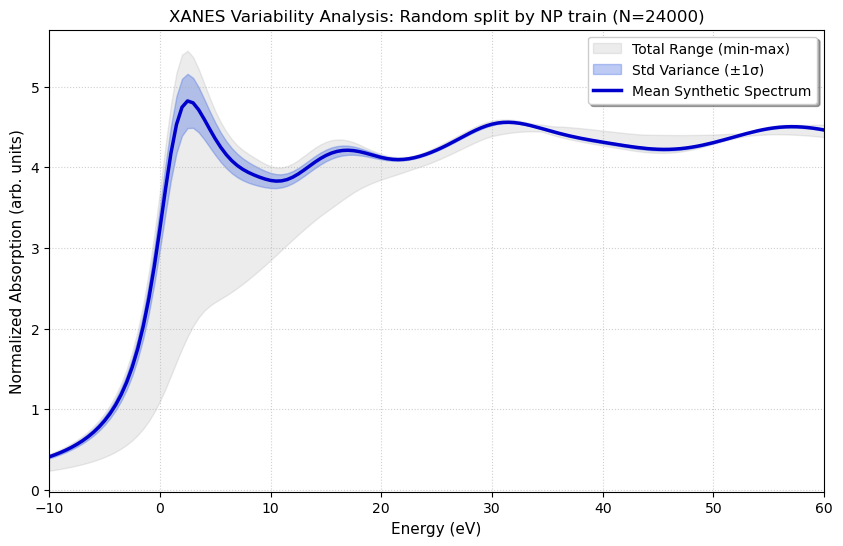

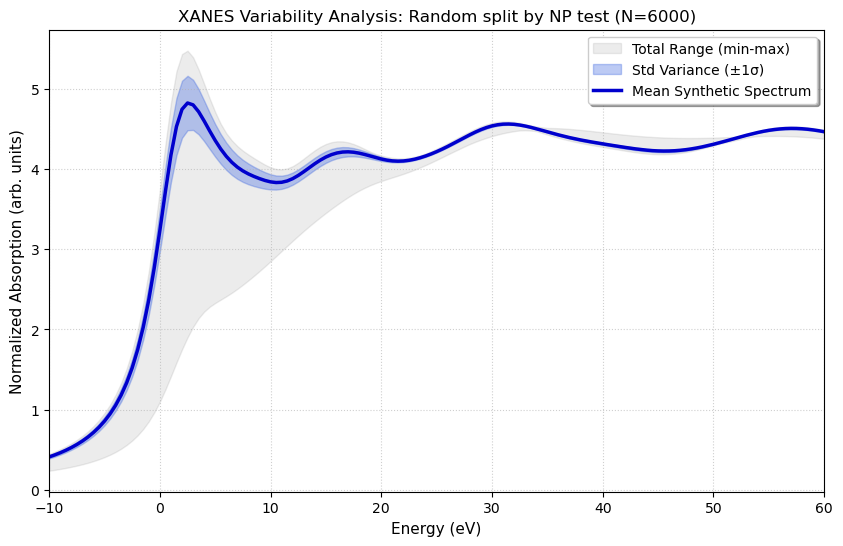

Y_train:


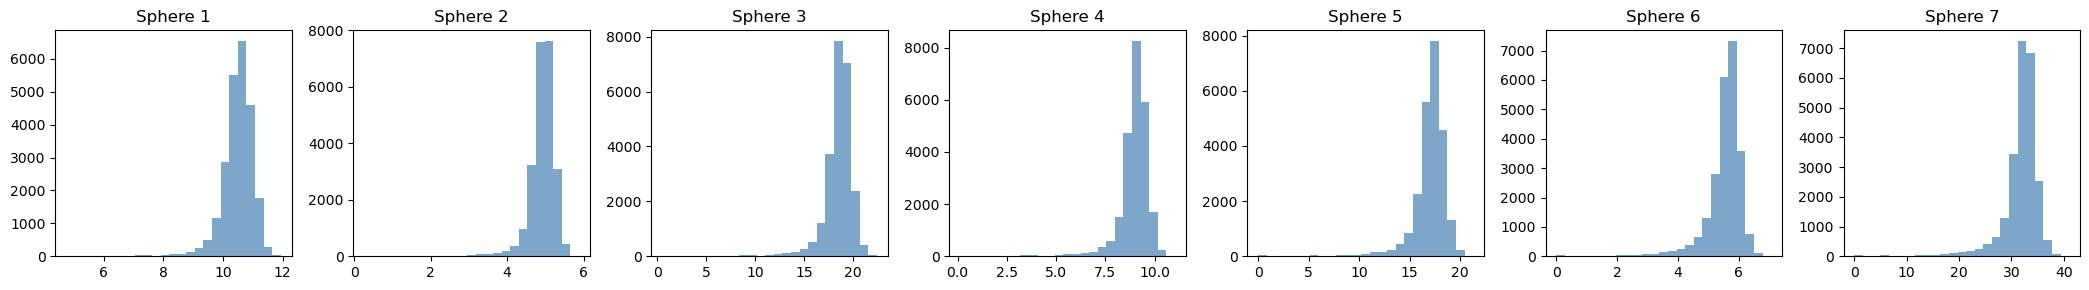

Y_test:


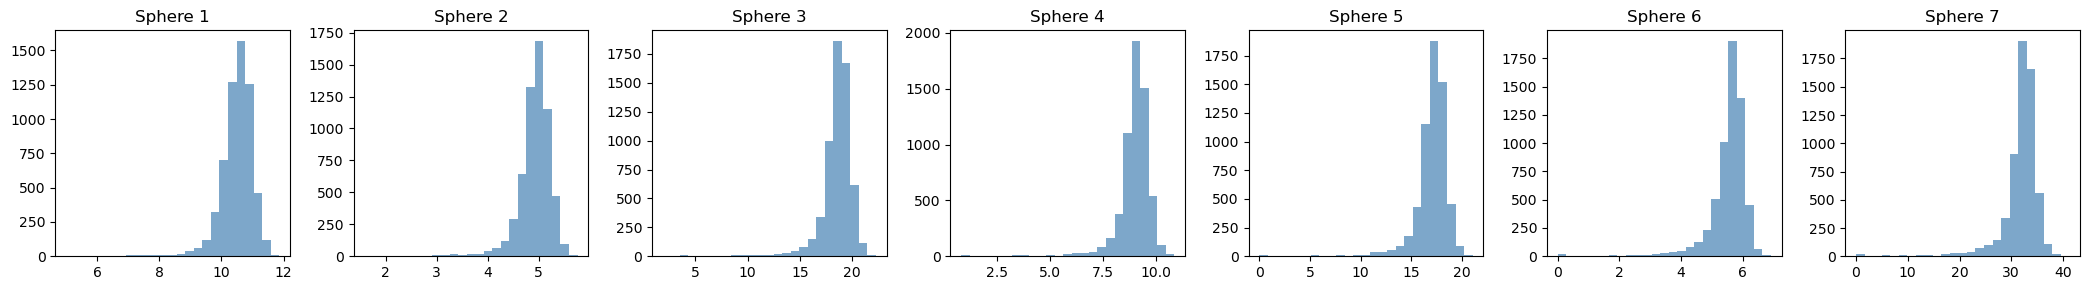

Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 2151 (пустые 0 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


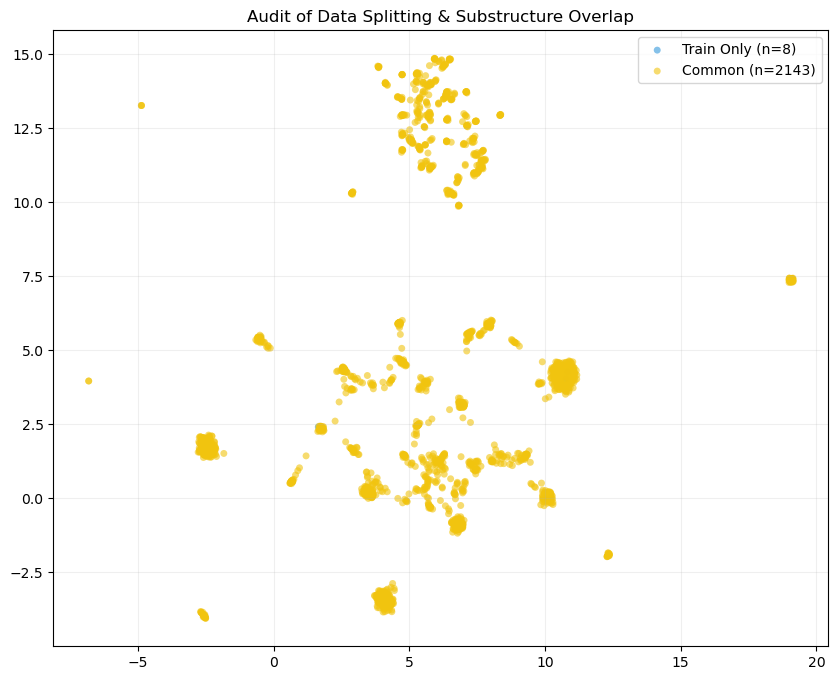

CPU times: total: 2min 58s
Wall time: 2min 43s


In [15]:
%%time
# Разбиваем на трейн и тест случайно
X_2A_train, X_2A_test, y_2A_train, y_2A_test,ind_tr, ind_te = train_test_split(X_2A_raw, y_2A_raw, np.arange(N_SAMPLES), 
                                                                               test_size=0.2, random_state=42)

save_name = str(Path(FIG_SAVE_PATH,f'Scenario_2A_Random_split_by_NPs'))


# Отрисуем вариантивность спектров при такой генерации.
plot_dataset_variability(X_data=X_2A_train, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Random split by NP train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_2A_test, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Random split by NP test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_2A_train,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_2A_test,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=weights_2A, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')

In [16]:
np.savez(Path(SAVE_DATA_PATH, 'No_Strict2A_Train_X'), X_2A_train) 
np.savez(Path(SAVE_DATA_PATH, 'No_Strict2A_Test_X'), X_2A_test)
np.savez(Path(SAVE_DATA_PATH, 'No_Strict2A_Train_y'), y_2A_train)
np.savez(Path(SAVE_DATA_PATH, 'No_Strict2A_Test_y'), y_2A_test) 

#### Scenario 2B - разбиваем данные на трейн и тест с помощью Lauvian_communities, размножение частиц по уже разделенным подструктурам. (С резервацией краевых НЧ для трейна)

In [17]:
%%time
# Используем только Train-частицы и разрешаем замены только на Train-подструктуры
X_2B_train, y_2B_train, w_2B_tr = gen.generate_honest_set(base_weights=NORMALISED_WEIGHTS[tr_sample_idx], 
                                                                      allowed_indices=tr_sub_idx, 
                                                                      n_samples_target=int(0.8*N_SAMPLES), # Целевое количество после фильтрации 
                                                                      p_subst=0.3, # 30% вероятность замены каждой компоненты 
                                                                      return_weights=True
                                                                     )

# Используем только Test-частицы и разрешаем замены только на Test-подструктуры
X_2B_test, y_2B_test, w_2B_te = gen.generate_honest_set(base_weights=NORMALISED_WEIGHTS[ts_sample_idx],
                                                                    allowed_indices=np.concatenate((shared_idx,ts_sub_idx)), # ts_sub_idx,
                                                                    n_samples_target=int(0.2*N_SAMPLES), 
                                                                    p_subst=0.3, 
                                                                    return_weights=True
                                                                   )

w_2B_all = np.concatenate((w_2B_tr,w_2B_te))
ind_tr = np.arange(w_2B_tr.shape[0])
ind_te = np.arange(w_2B_tr.shape[0],w_2B_all.shape[0],1)

CPU times: total: 1min 19s
Wall time: 1min 19s


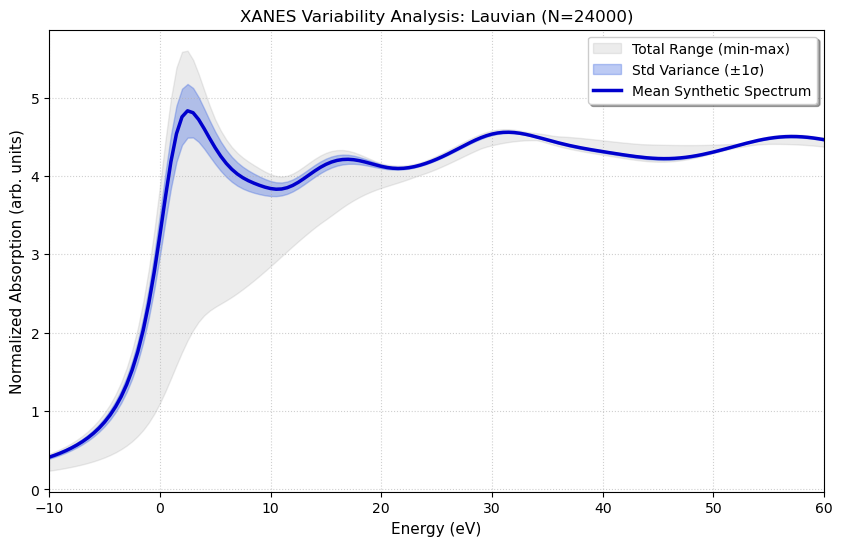

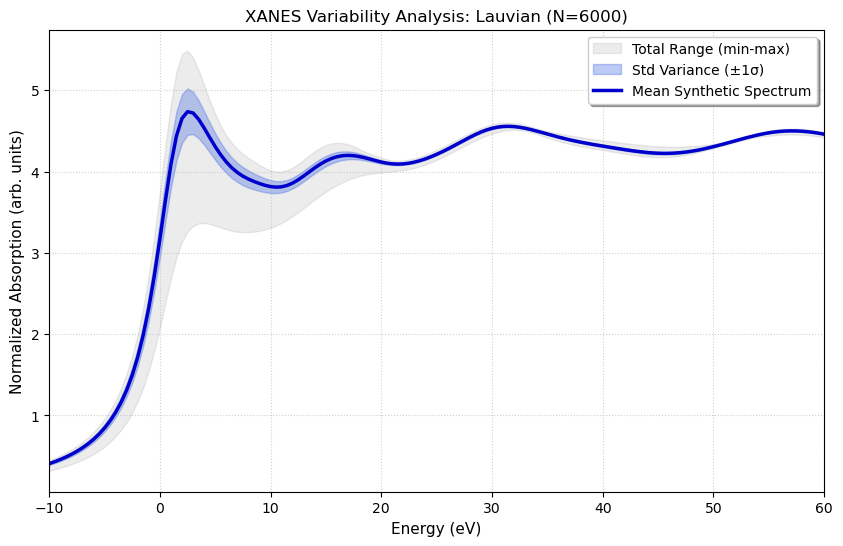

Y_train:


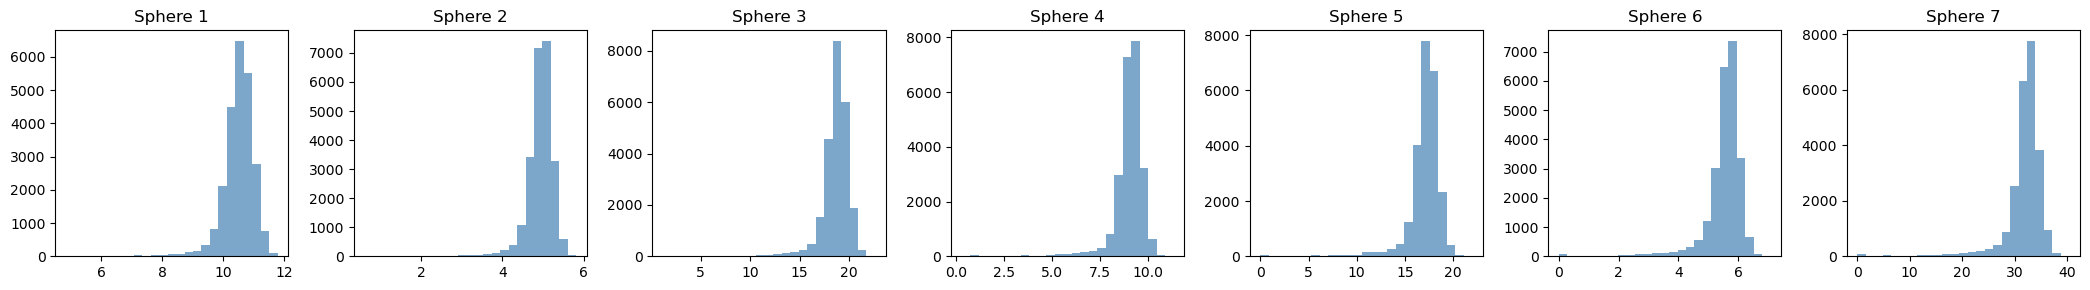

Y_test:


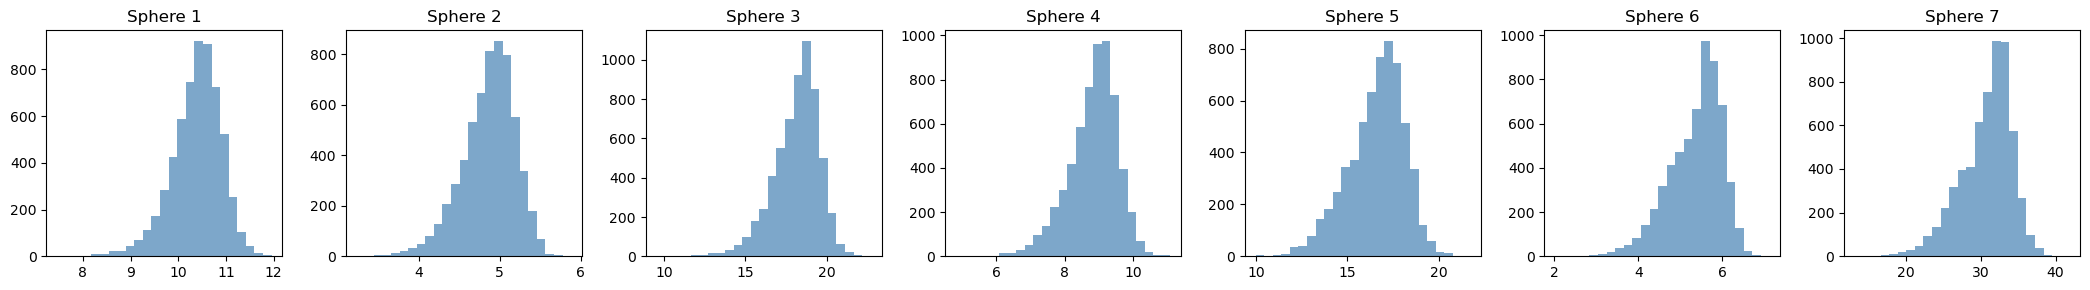

Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 2151 (пустые 0 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


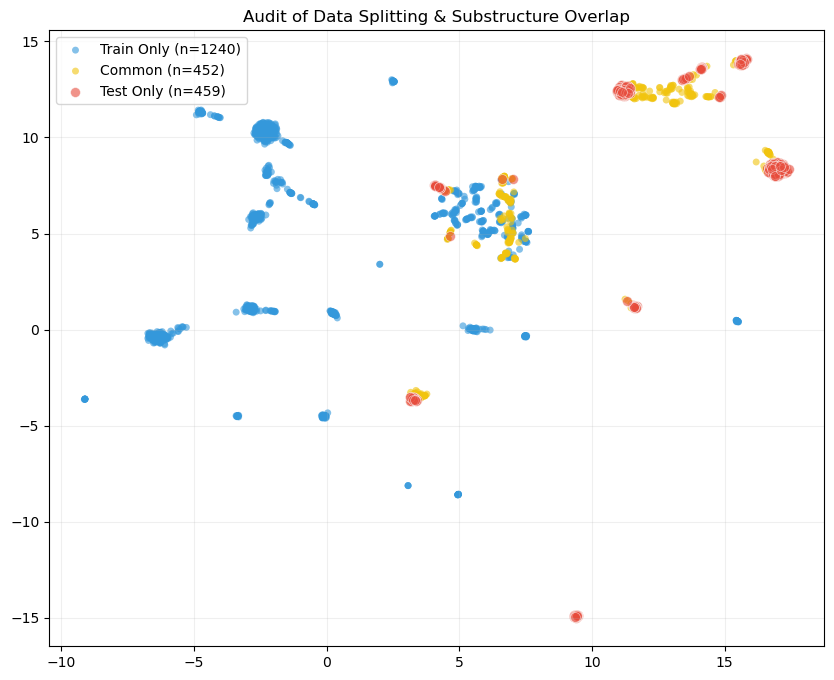

CPU times: total: 2min 53s
Wall time: 2min 41s


In [18]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Scenario_2B_Lauvian'))

plot_dataset_variability(X_data=X_2B_train, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Lauvian",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_2B_test, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Lauvian",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_2B_train,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_2B_test,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=w_2B_all, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')

In [19]:
np.savez(Path(SAVE_DATA_PATH, 'Lauvian2B_Train_X'), X_2B_train)
np.savez(Path(SAVE_DATA_PATH, 'Lauvian2B_Train_y'), y_2B_train)
np.savez(Path(SAVE_DATA_PATH, 'Lauvian2B_Test_X'), X_2B_test)
np.savez(Path(SAVE_DATA_PATH, 'Lauvian2B_Test_y'), y_2B_test)

### Scenario 3: Генерация наборов данных с реальными прообразами и "синтетическими" (k_mix=5) НЧ со строгим разделением и использованием фильтров.

In [20]:
filt = CompositeFilter(filters=[FCC_BulkCutFilter(),MinMaxFilter(),DummyFilter()])

СТАТИСТИКА СООБЩЕСТВ И РАЗБИЕНИЯ ВЫБОРКИ:
Объектов в Train: 725 | Объектов в Test: 75
Размер базиса подструктур: 2151 | Пересекающиеся подструктуры: 452 (21.0%)
Уникально подструктур в Train: 1240 | Уникально в Test: 459
Доля Test выборки внутри интервала [0.03,0.97] Train данных: 0.947
Кол-во краевых малых НЧ в Test выборке (ниже 0.03 квантиля Train): 0
Кол-во краевых крупных НЧ в Test выборке (выше 0.97 квантиля Train): 4
Находятся ли краевые значения Test данных полностью внутри Train данных: True
Тест Колмогорова-Смирнова  для размеров НЧ (Train==Test): 0.28598 | P-value: 0.00002
Тест Колмогорова-Смирнова  для размеров НЧ (Train>=Test): 0.05563 | P-value: 0.63047
Тест Колмогорова-Смирнова  для размеров НК (Train==Test): 0.06271 | P-value: 0.11208
Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): 0.05292 | P-value: 0.12676
Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 2151 (пустые 0 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


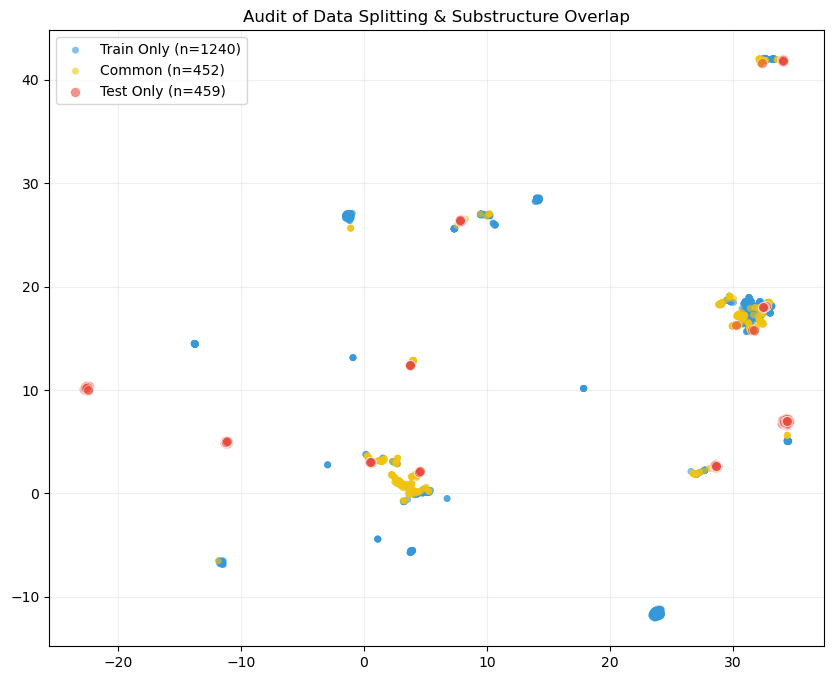

In [21]:
guaranteed_train_samples_idx = get_preserved_mask(weights_matrix=WEIGHTS_MATRIX,
                                                  sub_sizes=SUB_SIZES,
                                                  reconstruction_n_comp=2,        # Число компонент для PCA оценки ошибки реконструкции
                                                  reconstruction_top_repcent=3.0, # сколько топ % брать 
                                                  low_size_percentile=3.0,        # сколько % самых малых НЧ брать
                                                  high_size_percentile=0.1,       # сколько % самых крупных НЧ брать
                                                  masks_priorities=[3,2,1,0],     # [con_comp, recon_err, low_prc, high_prc]
                                                  max_base_percentile=5.0,        # Допустимый % данных для отобранных НЧ
                                                  max_tail_percentile=3.0,        # Допустимый процент "хвоста" для отобранных данных
                                                  tail_threshold=0.65,            # Порог вовлеченности подструктур чтобы затянуть в трейн
                                                  verbose=0, 
                                                  seed=42)

tr_sample_idx, ts_sample_idx, tr_sub_idx, ts_sub_idx, shared_idx = factory.get_community_split(
                                                                           WEIGHTS_MATRIX,
                                                                           resolution=2.5,
                                                                           threshold=0.75, 
                                                                           guaranteed_train_samples_idx = guaranteed_train_samples_idx,
                                                                           sub_sizes = SUB_SIZES,
                                                                           seed=123,
                                                                           return_shared_idx=True)

ts_sub_idx_with_shared = np.concatenate((shared_idx,ts_sub_idx))

plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=tr_sample_idx, 
                        test_sample_idx=ts_sample_idx, 
                        metric='dice')

#### Scenario 3A - аугментация спектров (массивов X) не применяется;

In [22]:
generator_3A = AdvancedDataGenerator(factory=factory, sigma=0.08, n_delta=4, aug_params=None, data_filter=filt)

In [23]:
%%time
X_3A_train_sint, y_3A_train_sint, w_3A_train_sint = generator_3A.generate_synthetic_set(tr_sub_idx, 
                                                                                        n_samples=int(0.4*N_SAMPLES), 
                                                                                        k_mix=5, 
                                                                                        return_weights=True)

X_3A_test_sint, y_3A_test_sint, w_3A_test_sint = generator_3A.generate_synthetic_set(ts_sub_idx_with_shared, n_samples=int(0.1*N_SAMPLES), return_weights=True)

X_3A_train_rl, y_3A_train_rl, w_3A_train_rl = generator_3A.generate_honest_set(base_weights=NORMALISED_WEIGHTS[tr_sample_idx], 
                                                                                allowed_indices=tr_sub_idx, 
                                                                                n_samples_target=int(0.4*N_SAMPLES),
                                                                                p_subst=0.3, 
                                                                                return_weights=True)


X_3A_test_rl, y_3A_test_rl, w_3A_test_rl = generator_3A.generate_honest_set(base_weights=NORMALISED_WEIGHTS[ts_sample_idx], 
                                                                                allowed_indices=ts_sub_idx_with_shared, 
                                                                                n_samples_target=int(0.1*N_SAMPLES),
                                                                                p_subst=0.3, 
                                                                                return_weights=True)

X_3A_train = np.concatenate((X_3A_train_sint, X_3A_train_rl))
X_3A_test  = np.concatenate((X_3A_test_sint,  X_3A_test_rl))

y_3A_train = np.concatenate((y_3A_train_sint, y_3A_train_rl))
y_3A_test  = np.concatenate((y_3A_test_sint,  y_3A_test_rl))

w_3A_train = np.concatenate((w_3A_train_sint, w_3A_train_rl))
w_3A_test  = np.concatenate((w_3A_test_sint,  w_3A_test_rl))

w_3A_all = np.concatenate((w_3A_train,w_3A_test))
ind_tr = np.arange(w_3A_train.shape[0])
ind_te = np.arange(w_3A_train.shape[0],w_3A_all.shape[0],1)

CPU times: total: 1min 23s
Wall time: 1min 24s


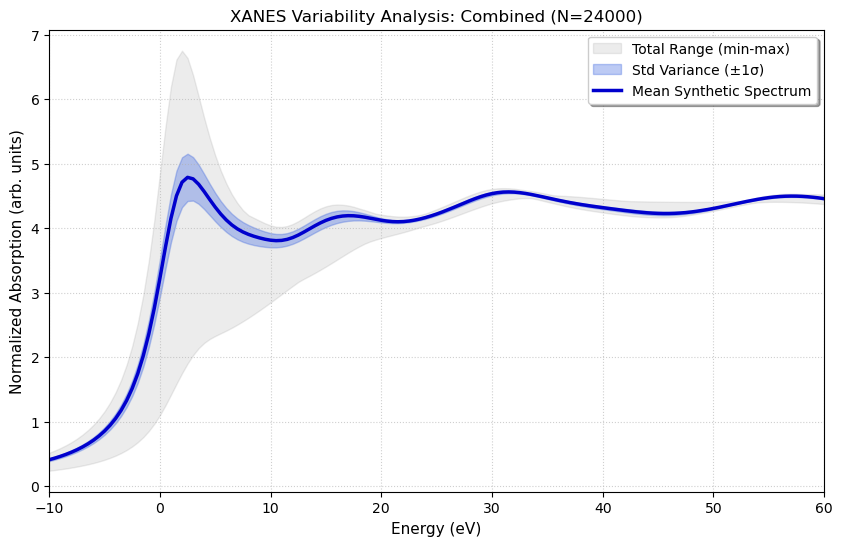

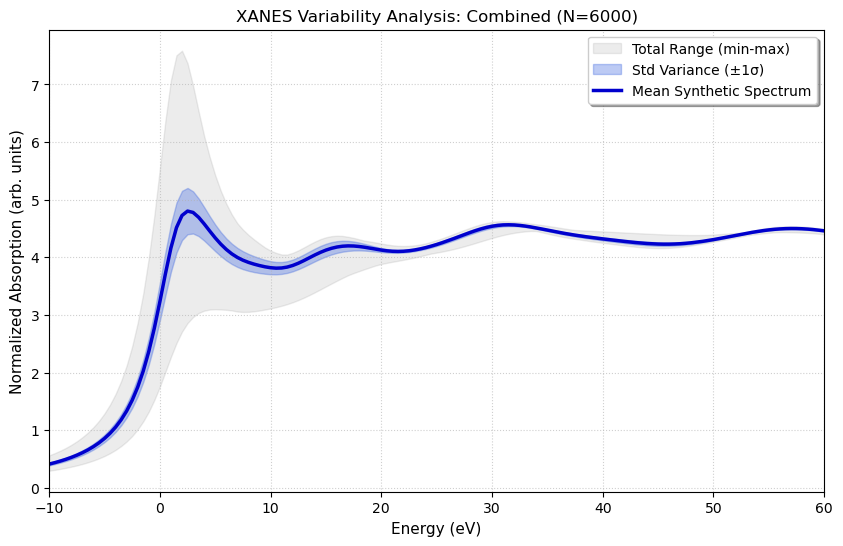

Y_train:


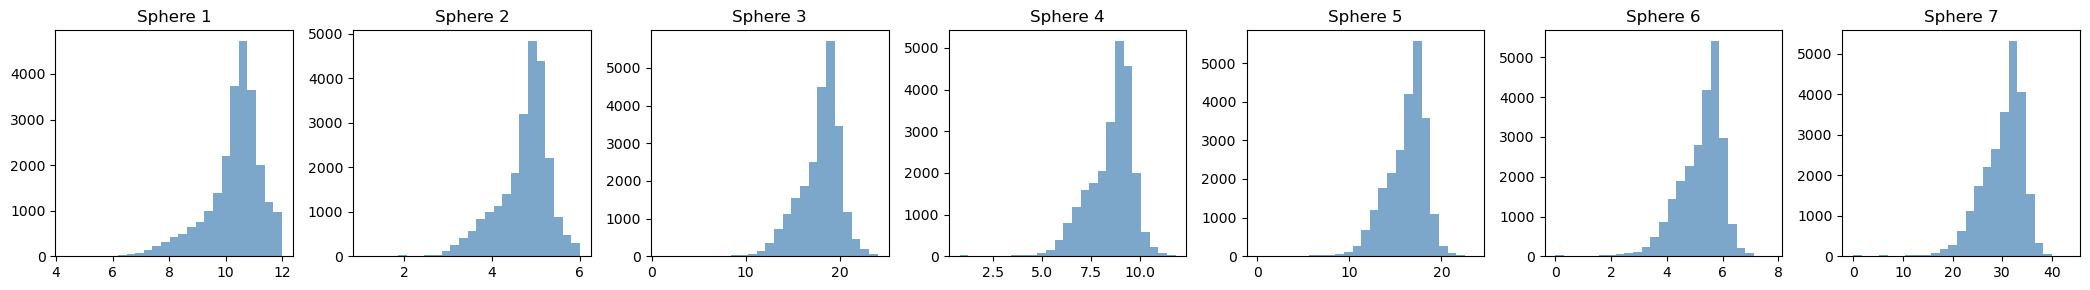

Y_test:


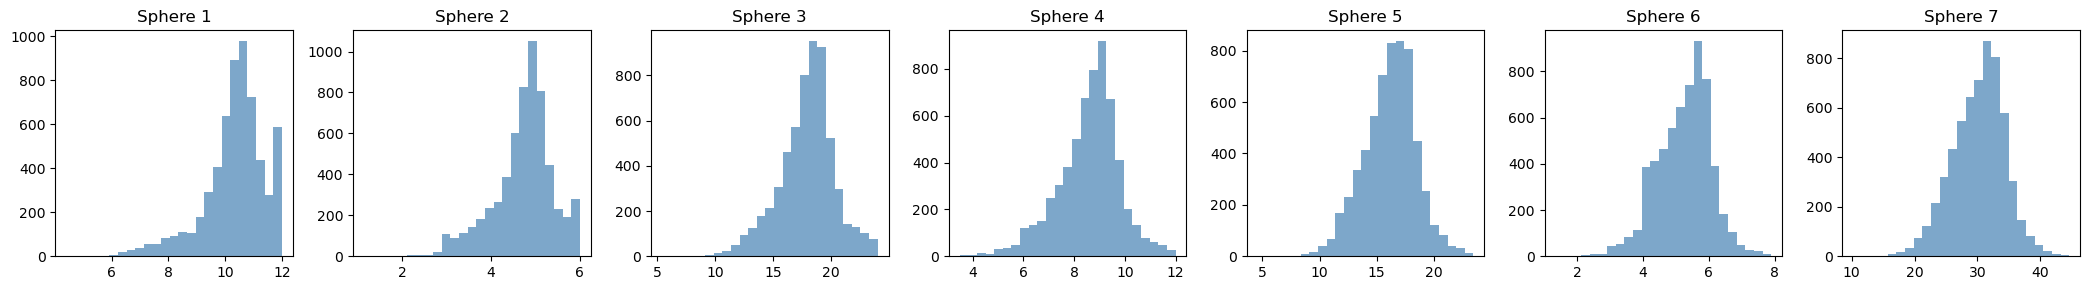

Всего подструктур в базисе: 2151
Активных подструктур для UMAP: 2151 (пустые 0 отброшены)
Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


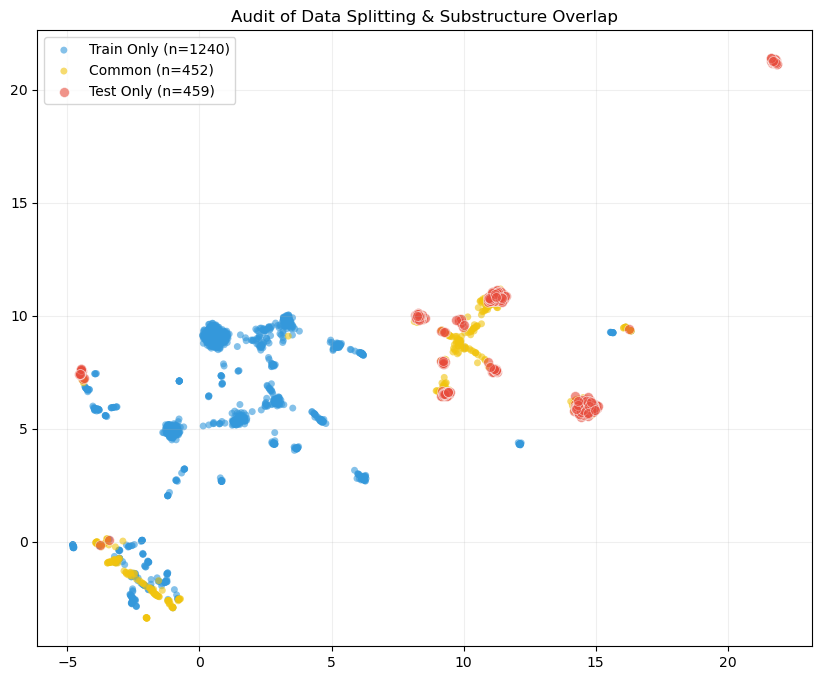

CPU times: total: 3min 9s
Wall time: 2min 48s


In [24]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Scenario_3A_combined'))

plot_dataset_variability(X_data=X_3A_train, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, 
                         title_suffix=f"Combined",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_3A_test, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Combined",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_3A_train,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_3A_test,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=w_3A_all, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')

In [25]:
np.savez(Path(SAVE_DATA_PATH, 'Combined_No_Aug_3A_Train_X'), X_3A_train)
np.savez(Path(SAVE_DATA_PATH, 'Combined_No_Aug_3A_Train_y'), y_3A_train)
np.savez(Path(SAVE_DATA_PATH, 'Combined_No_Aug_3A_Test_X'),  X_3A_test)
np.savez(Path(SAVE_DATA_PATH, 'Combined_No_Aug_3A_Test_y'),  y_3A_test)